In [3]:

# STEP 1: DOWNLOAD AND LOAD SMS SPAM DATASET

import pandas as pd
import urllib.request
import zipfile
import os

# Download the dataset
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/00228/smsspamcollection.zip"
)

zip_path = "/content/sms_spam_collection.zip"
extract_path = "/content/sms_spam_dataset"

print("Downloading SMS Spam Collection dataset...")

urllib.request.urlretrieve(url, zip_path)

# Extract dataset files
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

# Load the text dataset into df
dataset_path = os.path.join(
    extract_path, "SMSSpamCollection"
)

df = pd.read_csv(
    dataset_path,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

# Remove duplicate messages
df = df.drop_duplicates().dropna().reset_index(drop=True)

# Display dataset information
print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nClass distribution:")
print(df["label"].value_counts())

print("\nFirst five messages:")
display(df.head())



Dataset loaded successfully!
Dataset shape: (5169, 2)

Class distribution:
label
ham     4516
spam     653
Name: count, dtype: int64

First five messages:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:

# STEP 2: PREPROCESS TEXT AND CREATE TF-IDF FEATURES

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X = df["message"].astype(str)
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF preparation completed!")
print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)


TF-IDF preparation completed!
Training feature shape: (4135, 10000)
Testing feature shape: (1034, 10000)


In [5]:

# STEP 3: TRAIN AND COMPARE THREE ML ALGORITHMS

import time
import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Define models
models = {
    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute"
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=30,
        random_state=42
    ),

    "SVM": LinearSVC(
        random_state=42,
        max_iter=5000
    )
}

results = []
predictions = {}
trained_models = {}

# Train and test each model
for name, model in models.items():

    print(f"\nTraining {name}...")

    start = time.perf_counter()
    model.fit(X_train_tfidf, y_train)
    training_time = time.perf_counter() - start

    y_pred = model.predict(X_test_tfidf)

    predictions[name] = y_pred
    trained_models[name] = model

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred,
            pos_label="spam",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred,
            pos_label="spam",
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred,
            pos_label="spam",
            zero_division=0
        ),
        "Training Time (seconds)": training_time
    })

    print(f"{name} completed!")

# Show comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("\n===== MODEL COMPARISON RESULTS =====")
display(results_df.round(4))

# Save comparison table
results_df.to_csv(
    "algorithm_comparison_3_models.csv",
    index=False
)

# Display the best model
best = results_df.iloc[0]

print("\n===== BEST MODEL =====")
print("Algorithm:", best["Algorithm"])
print(f"Accuracy:  {best['Accuracy']:.4f}")
print(f"Precision: {best['Precision']:.4f}")
print(f"Recall:    {best['Recall']:.4f}")
print(f"F1-Score:  {best['F1-Score']:.4f}")



Training KNN...
KNN completed!

Training Decision Tree...
Decision Tree completed!

Training SVM...
SVM completed!

===== MODEL COMPARISON RESULTS =====


,Algorithm,Accuracy,Precision,Recall,F1-Score,Training Time (seconds)
0,SVM,0.9787,0.9580,0.8702,0.9120,0.0218
1,Decision Tree,0.9623,0.9035,0.7863,0.8408,0.4576
2,KNN,0.9594,0.9785,0.6947,0.8125,0.0134



===== BEST MODEL =====
Algorithm: SVM
Accuracy:  0.9787
Precision: 0.9580
Recall:    0.8702
F1-Score:  0.9120


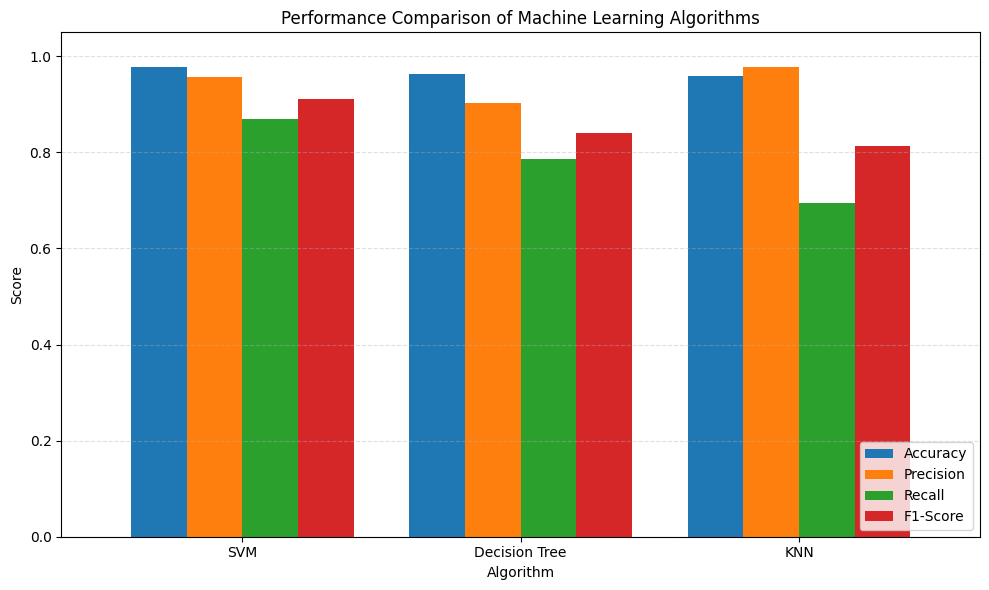

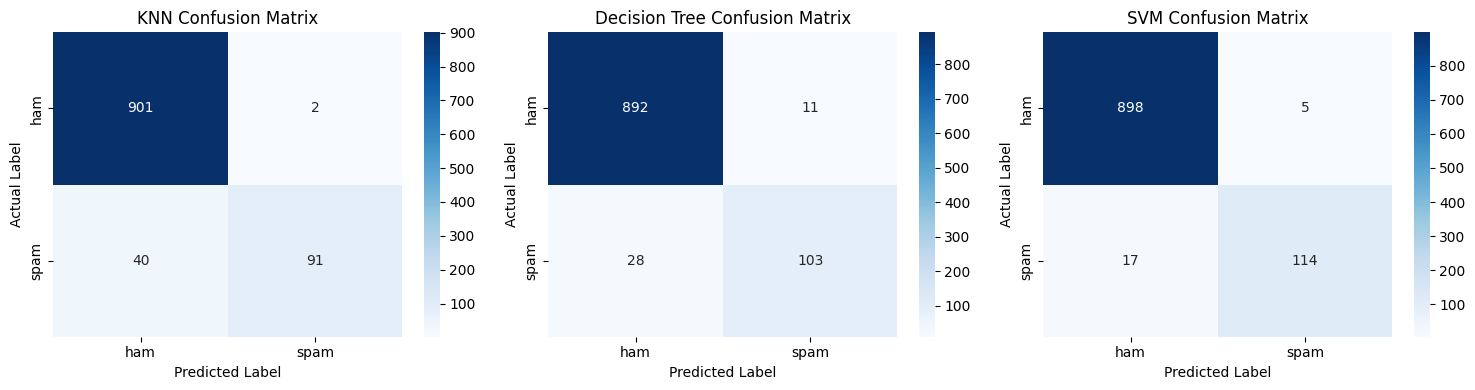

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. Compare model performance
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_plot = results_df.set_index("Algorithm")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.05),
    width=0.8
)

plt.title("Performance Comparison of Machine Learning Algorithms")
plt.ylabel("Score")
plt.xlabel("Algorithm")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300)
plt.show()


# 2. Confusion matrices for all three algorithms
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["ham", "spam"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["ham", "spam"],
        yticklabels=["ham", "spam"],
        ax=ax
    )

    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=300)
plt.show()

In [7]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import time

# Train Naive Bayes
nb_model = MultinomialNB()

start_time = time.time()
nb_model.fit(X_train_tfidf, y_train)
nb_predictions = nb_model.predict(X_test_tfidf)
nb_time = time.time() - start_time

# Evaluate Naive Bayes
nb_results = {
    "Algorithm": "Naive Bayes",
    "Accuracy": accuracy_score(y_test, nb_predictions),
    "Precision": precision_score(
        y_test, nb_predictions, pos_label="spam", zero_division=0
    ),
    "Recall": recall_score(
        y_test, nb_predictions, pos_label="spam", zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, nb_predictions, pos_label="spam", zero_division=0
    ),
    "Training Time (seconds)": nb_time
}

print("Naive Bayes Results:")
for metric, value in nb_results.items():
    print(f"{metric}: {value:.4f}" if isinstance(value, float) else f"{metric}: {value}")

Naive Bayes Results:
Algorithm: Naive Bayes
Accuracy: 0.9652
Precision: 1.0000
Recall: 0.7252
F1-Score: 0.8407
Training Time (seconds): 0.0171


In [8]:
import pandas as pd

# Add Naive Bayes results to the existing comparison table
all_results = results_df.copy()

nb_row = pd.DataFrame([nb_results])
all_results = pd.concat([all_results, nb_row], ignore_index=True)

# Sort by F1-score
all_results = all_results.sort_values(
    by="F1-Score", ascending=False
).reset_index(drop=True)

# Display the final comparison table
print("===== FINAL COMPARISON OF FOUR ALGORITHMS =====")
display(all_results.round(4))

# Save the results as a CSV file
all_results.to_csv(
    "final_algorithm_comparison.csv", index=False
)

# Identify the best model
best_model = all_results.iloc[0]

print("\n===== BEST MODEL =====")
print("Algorithm:", best_model["Algorithm"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1-Score:", round(best_model["F1-Score"], 4))

===== FINAL COMPARISON OF FOUR ALGORITHMS =====


,Algorithm,Accuracy,Precision,Recall,F1-Score,Training Time (seconds)
0,SVM,0.9787,0.9580,0.8702,0.9120,0.0218
1,Decision Tree,0.9623,0.9035,0.7863,0.8408,0.4576
2,Naive Bayes,0.9652,1.0000,0.7252,0.8407,0.0171
3,KNN,0.9594,0.9785,0.6947,0.8125,0.0134



===== BEST MODEL =====
Algorithm: SVM
Accuracy: 0.9787
Precision: 0.958
Recall: 0.8702
F1-Score: 0.912


In [9]:
from google.colab import files

files.download("final_algorithm_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
from sklearn.metrics import classification_report
import pandas as pd

# Store predictions from all four algorithms
all_predictions = {
    "KNN": predictions["KNN"],
    "Decision Tree": predictions["Decision Tree"],
    "SVM": predictions["SVM"],
    "Naive Bayes": nb_predictions
}

for model_name, y_pred in all_predictions.items():
    print("\n" + "=" * 55)
    print(f"CLASSIFICATION REPORT: {model_name}")
    print("=" * 55)

    print(classification_report(
        y_test,
        y_pred,
        labels=["ham", "spam"],
        target_names=["Ham (Not Spam)", "Spam"],
        zero_division=0
    ))


CLASSIFICATION REPORT: KNN
                precision    recall  f1-score   support

Ham (Not Spam)       0.96      1.00      0.98       903
          Spam       0.98      0.69      0.81       131

      accuracy                           0.96      1034
     macro avg       0.97      0.85      0.89      1034
  weighted avg       0.96      0.96      0.96      1034


CLASSIFICATION REPORT: Decision Tree
                precision    recall  f1-score   support

Ham (Not Spam)       0.97      0.99      0.98       903
          Spam       0.90      0.79      0.84       131

      accuracy                           0.96      1034
     macro avg       0.94      0.89      0.91      1034
  weighted avg       0.96      0.96      0.96      1034


CLASSIFICATION REPORT: SVM
                precision    recall  f1-score   support

Ham (Not Spam)       0.98      0.99      0.99       903
          Spam       0.96      0.87      0.91       131

      accuracy                           0.98      1034
  

THREE-ALGORITHM PERFORMANCE COMPARISON


,Algorithm,Accuracy,Precision,Recall,F1-Score,Training Time (seconds)
0,SVM,0.9787,0.9580,0.8702,0.9120,0.0218
1,Decision Tree,0.9623,0.9035,0.7863,0.8408,0.4576
2,KNN,0.9594,0.9785,0.6947,0.8125,0.0134



BEST PERFORMING ALGORITHM
Algorithm: SVM
Accuracy:  0.9787
Precision: 0.9580
Recall:    0.8702
F1-score:  0.9120


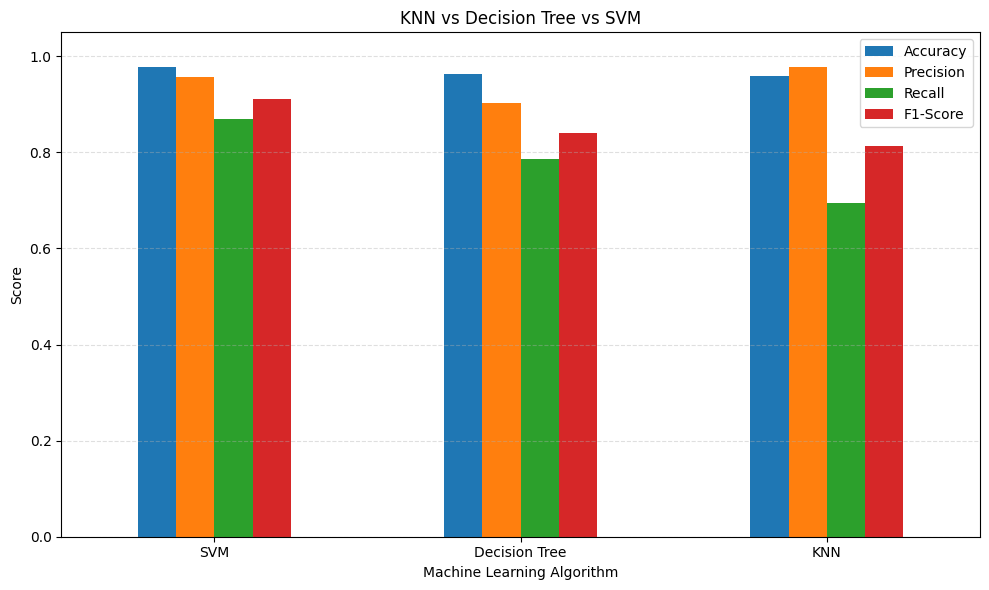

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# Use the results already obtained from your three models
comparison = results_df[
    [
        "Algorithm",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "Training Time (seconds)"
    ]
].copy()

# Keep only the required three algorithms
comparison = comparison[
    comparison["Algorithm"].isin(
        ["KNN", "Decision Tree", "SVM"]
    )
]

# Sort by F1-score
comparison = comparison.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("THREE-ALGORITHM PERFORMANCE COMPARISON")
display(comparison.round(4))

# Identify the best model
best = comparison.iloc[0]

print("\nBEST PERFORMING ALGORITHM")
print("Algorithm:", best["Algorithm"])
print(f"Accuracy:  {best['Accuracy']:.4f}")
print(f"Precision: {best['Precision']:.4f}")
print(f"Recall:    {best['Recall']:.4f}")
print(f"F1-score:  {best['F1-Score']:.4f}")

# Plot comparison
comparison.set_index("Algorithm")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(kind="bar", figsize=(10, 6), ylim=(0, 1.05))

plt.title("KNN vs Decision Tree vs SVM")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("three_algorithm_comparison.png", dpi=300)
plt.show()

# Save the comparison table
comparison.to_csv(
    "three_algorithm_comparison.csv",
    index=False
)

In [12]:
from google.colab import files
import os

# Download the comparison table
if os.path.exists("final_algorithm_comparison.csv"):
    files.download("final_algorithm_comparison.csv")

# Download the performance graph
if os.path.exists("model_comparison.png"):
    files.download("model_comparison.png")

# Download the confusion matrices
if os.path.exists("confusion_matrices.png"):
    files.download("confusion_matrices.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>